# Radio-map benchmark, round 2: a pre-specified replication on fresh data

**Status: written, not executed.** Nothing in this notebook has been run on your machine's data. The plumbing (adapter, new methods, reports, claim rule) was dry-run on fake data and on the real SOD files with the neural model stubbed out, so the *numbers* below will be the first real ones.

Round 1 (`radiomap_ext_real_crosslayout.ipynb`) stays untouched. This notebook answers the two follow-ups you picked:

| follow-up | what is implemented | where |
|---|---|---|
| New pre-registered contrasts on fresh salts and replicates | `kgnn` vs `krig_global` (primary H4); `kgnn_side` vs `rk_side` (primary H5) plus three single-factor companions; new test salt `conf2`, new replicate ids, new wall layouts, new UJI APs (disjoint from round 1), hash-frozen plan `prereg_conf2.json` | sections 2, 4, 5, 7 |
| One more real dataset with more independent layouts | **SODIndoorLoc**: 3 buildings in different cities (UJI has 3 too, so 6 buildings pooled), 5 building-floors, 100+ RPs per floor so densities up to 60 are possible | section 3 |

Two honest limits that shape everything below:

* **The contrasts were chosen after seeing round 1.** What is fresh is the *data* (new UJI APs, SOD, new wall layouts, new test salt, new replicates), not the hypotheses. The plan says so in its own text. DeepMIMO `dm_path` reuses the same transmitters, so only salt and replicates are fresh there, and it is never used to support a claim.
* **SOD adds buildings, not many floors.** CETC331 has 3 floors; HCXY and SYL have one each. The real-data count goes from 12 floors / 3 buildings to 17 floors / 6 buildings. Six buildings is still small, so the primary real-data inference is reported at two levels: floor-level Holm tests (as in round 1) **and** a building-level cluster bootstrap that treats buildings as the independent unit.

Files needed next to this notebook: `rmbench_core.py`, `rmbench_nn.py`, `rmbench_ext.py`, `rmbench_ext2.py`, `run_ext.py` (all unchanged) and the new `rmbench_ext3.py`. DeepMIMO needs its package and network (as in round 1); SOD and UJI download if the files are not in `data/`.

## 1. Setup

In [1]:
import os, sys, json, warnings, shutil
sys.path.insert(0, os.getcwd())
warnings.filterwarnings("ignore")

def _preflight():
    need = ["rmbench_core.py", "rmbench_nn.py", "rmbench_ext.py", "rmbench_ext2.py", "rmbench_ext3.py", "run_ext.py"]
    gone = [f for f in need if not os.path.exists(f)]
    if gone: raise FileNotFoundError(f"missing next to the notebook ({os.getcwd()}): {gone}")
    ext, ext2, ext3 = (open(f).read() for f in ("rmbench_ext.py", "rmbench_ext2.py", "rmbench_ext3.py"))
    if "rmbench_ext as rx" in ext: raise RuntimeError("rmbench_ext.py contains later-layer code (it imports itself). Restore the ORIGINAL rmbench_ext.py.")
    if "rmbench_ext as rx" not in ext2 or "rmbench_ext3" in ext2: raise RuntimeError("rmbench_ext2.py is not the second layer (or it was overwritten by the third).")
    if "rmbench_ext2 as r2" not in ext3: raise RuntimeError("rmbench_ext3.py does not look like the third layer (it should import rmbench_ext2 as r2).")
_preflight()
for _m in ("rmbench_ext", "rmbench_ext2", "rmbench_ext3"): sys.modules.pop(_m, None)

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
import rmbench_core as rc, rmbench_ext as rx, rmbench_ext2 as r2, rmbench_ext3 as r3
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)

SMOKE  = False         # True: dry run on FAKE data (UJI-like, SOD-like, small wall set, no DeepMIMO). Says nothing about science. Wipes nb3_smoke/.
N_JOBS = max(1, (os.cpu_count() or 2) - 1)
ROOT   = "nb3_smoke" if SMOKE else "results_conf2"
R1     = "results_ext2"       # round-1 folder: only READ (unit names to exclude, prereg hash, master table). Never written.
if SMOKE: shutil.rmtree(ROOT, ignore_errors=True)
os.makedirs(ROOT, exist_ok=True)
WANT = ["uji", "sod", "wall"] if SMOKE else ["uji", "sod", "wall", "dm_path"]

S = dict(n_rep=2 if SMOKE else 5, uji_aps=2 if SMOKE else 8, sod_aps=2 if SMOKE else 10,
         min_floors=6 if SMOKE else 13, uji_floors_assert=4 if SMOKE else 10, sod_floors_assert=5,
         n_layouts_wall=4 if SMOKE else 16, n_tx_wall=2 if SMOKE else 6, wall_pts=250 if SMOKE else 500,
         wall_dens=(20, 40, 60) if SMOKE else (20, 50, 100), wall_ntest=100 if SMOKE else 200, max_dm_units=6 if SMOKE else 24)
print("SMOKE" if SMOKE else "REAL", "| jobs:", N_JOBS, "| families:", WANT)

REAL | jobs: 15 | families: ['uji', 'sod', 'wall', 'dm_path']


## 2. Real data A: UJIIndoorLoc, a fresh AP sample
Same data-only setting rule as round 1 (`suggest_wifi_setting`), but the per-floor AP cap is filled with **APs that round 1 did not use** (`exclude=` the round-1 unit names, read from `results_ext2/cache_uji`). Seed 2 instead of 1.

In [2]:
csv_dir = rx.make_fake_uji(f"{ROOT}/fake_uji", floors=(2, 2, 2), n_waps=12) if SMOKE else rx.fetch_uji("data/ujiindoorloc")
uji_df = r2.read_uji(csv_dir)
tab = r2.wifi_floor_table(uji_df, **r2.UJI_COLS)
sug_table, SUG = r2.suggest_wifi_setting(tab, min_floors=S["min_floors"], min_aps=3)
print("chosen (same rule as round 1):", SUG)

EXCL_UJI = set() if SMOKE else r3.units_in_cache(f"{R1}/cache_uji")
print("round-1 UJI units that will be excluded:", len(EXCL_UJI), "(0 means the round-1 cache was not found: units are then new only by seed)")
UJI = dict(rx.UJI_CFG, cache_dir=f"{ROOT}/cache_uji", densities=SUG["densities"], n_test=SUG["n_test"], min_unit_points=SUG["min_unit_points"],
           min_det_frac=SUG["min_det_frac"], uji_max_waps_per_floor=S["uji_aps"], n_rep=S["n_rep"],
           outage_q=(0.25, 0.5), outage_abs_dbm=(), outage_min_class=8, trend_policy="robust", seed=2)
ok_uji, rec_uji = r3.build_wifi_units3(uji_df, UJI, "uji", **r2.UJI_COLS, exclude=EXCL_UJI)
display(rec_uji.groupby(["building", "floor", "reason"]).size().unstack(fill_value=0))
meta = pd.DataFrame([dict(unit=n, layout=(u := rx.get_unit_ext(n, UJI["cache_dir"]))["layout"], parent=u["parent"], n_pts=len(u["y"])) for n in ok_uji])
print(f"{len(ok_uji)} units | {meta.parent.nunique()} building-floors | {meta.layout.nunique()} buildings | overlap with round 1: {len(set(ok_uji) & EXCL_UJI)}")
assert not (set(ok_uji) & EXCL_UJI), "round-2 UJI units overlap round 1"
assert meta.parent.nunique() >= S["uji_floors_assert"], "too few UJI floors for inference; read the table above (same remedy as in round 1)"
FAMILY_DEFS = {"uji": dict(names=ok_uji, cfg=UJI, side=False, by="parent", infer=None)}

chosen (same rule as round 1): {'densities': (5, 10, 20), 'n_test': 20, 'min_unit_points': 41, 'min_det_frac': 0.3, 'floors_ok': 12, 'reached': False}
round-1 UJI units that will be excluded: 96 (0 means the round-1 cache was not found: units are then new only by seed)


reason          cut by per-floor cap  excluded (used in round 1)  kept  too few detected points
building floor                                                                                 
0        0                         3                           8     8                       93
         1                        31                           8     8                      111
         2                        29                           8     8                      126
         3                         6                           8     8                      155
1        0                         0                           8     1                      117
         1                        12                           8     8                      135
         2                         3                           8     8                      163
         3                         0                           0     0                      138
2        0                         3                           8     8                       66
         1                        28                           8     8                       95
         2                        19                           8     8                       83
         3                        16                           8     8                      104
         4                         3                           8     8                      114

89 units | 12 building-floors | 3 buildings | overlap with round 1: 0


## 3. Real data B: SODIndoorLoc (new)
Source: Bi et al., *Satellite Navigation* 3, 25 (2022), repository `bijingxue/SODIndoorLoc`. Schema checked by downloading the three sheets once: columns `MAC<k>`, `ECoord`, `NCoord`, `FloorID`, `BuildingID`; not detected = `100`; RSS from -104 to 0.

| building | sheet used | floors | RPs per floor | raw captures per RP | pre-installed AP MACs |
|---|---|---|---|---|---|
| 1 CETC331 | `Training_CETC331.csv` | 1, 2, 3 | 285 / 340 / 330 | 1 | 52 |
| 2 HCXY | `Training_HCXY_AP_30.csv` | 4 | 379 | 30 | 56 |
| 3 SYL | `Training_SYL_AP_30.csv` | 4 | 296 | 30 | 46 |

Choices, so they are not a surprise later: the `_30` sheets (raw captures, 100 = not detected) rather than `_Avg` (those code not-detected as -105, which mixes level and detection); pre-installed APs only (the `All` sheets add ambient APs of unknown location; the SYL `All_Avg` sheet also has an irregular `BuildingID` column); AP positions from the xlsx are **not** used, so the transmitter is localised from labels exactly as for UJI. A unit is one AP on one floor, layout = building, parent = building-floor. Densities are `(5, 10, 20)` (shared with UJI, so the two can be pooled) plus the dense setting chosen by the data-only rule.

In [3]:
SOD_DIR = r3.make_fake_sod(f"{ROOT}/fake_sod") if SMOKE else r3.fetch_sod("data/sodindoorloc")
sod_df = r3.read_sod(SOD_DIR)
tab_s = r2.wifi_floor_table(sod_df, **r3.SOD_COLS, wprefix=r3.SOD_PREFIX)
display(tab_s[tab_s.det_frac == 0.5].pivot_table(index=["building", "floor"], columns="min_points", values="n_aps"))
ts_table, SS = r2.suggest_wifi_setting(tab_s, min_floors=S["sod_floors_assert"], min_aps=3)
SOD_DENS = tuple(sorted(set(UJI["densities"]) | {SS["densities"][-1]}))
print("data-only rule picked:", SS, "-> SOD densities", SOD_DENS)
SOD = dict(rx.UJI_CFG, cache_dir=f"{ROOT}/cache_sod", densities=SOD_DENS, n_test=SS["n_test"], min_unit_points=max(SS["min_unit_points"], max(SOD_DENS) + SS["n_test"] + 1),
           min_det_frac=SS["min_det_frac"], uji_max_waps_per_floor=S["sod_aps"], n_rep=S["n_rep"],
           outage_q=(0.25, 0.5), outage_abs_dbm=(), outage_min_class=8, trend_policy="robust", seed=2)
ok_sod, rec_sod = r3.build_wifi_units3(sod_df, SOD, "sod", **r3.SOD_COLS, wprefix=r3.SOD_PREFIX)
display(rec_sod.groupby(["building", "floor", "reason"]).size().unstack(fill_value=0))
metaS = pd.DataFrame([dict(unit=n, layout=(u := rx.get_unit_ext(n, SOD["cache_dir"]))["layout"], parent=u["parent"], n_pts=len(u["y"])) for n in ok_sod])
print(f"{len(ok_sod)} units | {metaS.parent.nunique()} building-floors | {metaS.layout.nunique()} buildings   (layouts: sod_b1 = CETC331, sod_b2 = HCXY, sod_b3 = SYL)")
display(metaS.groupby("parent").n_pts.agg(["size", "min", "median", "max"]))
assert metaS.parent.nunique() >= S["sod_floors_assert"], "SOD should give 5 building-floors; check the three CSVs"
FAMILY_DEFS["sod"] = dict(names=ok_sod, cfg=SOD, side=False, by="parent", infer=None)

downloading https://raw.githubusercontent.com/bijingxue/SODIndoorLoc/main/CETC331/Training_CETC331.csv
downloading https://raw.githubusercontent.com/bijingxue/SODIndoorLoc/main/HCXY/Training_HCXY_AP_30.csv
downloading https://raw.githubusercontent.com/bijingxue/SODIndoorLoc/main/SYL/Training_SYL_AP_30.csv


min_points       41    51    61    76    86    101   110
building floor                                          
1        1      39.0  39.0  35.0  35.0  35.0  32.0  30.0
         2      39.0  36.0  36.0  36.0  35.0  33.0  33.0
         3      28.0  28.0  28.0  28.0  27.0  26.0  26.0
2        4      51.0  48.0  48.0  38.0  26.0  17.0  11.0
3        4      44.0  42.0  40.0  37.0  32.0  30.0  20.0

data-only rule picked: {'densities': (15, 30, 60), 'n_test': 40, 'min_unit_points': 101, 'min_det_frac': 0.5, 'floors_ok': 5, 'reached': True} -> SOD densities (5, 10, 20, 60)


reason          cut by per-floor cap  kept  too few detected points
building floor                                                     
1        1                        22    10                       11
         2                        23    10                       13
         3                        16    10                        3
2        4                         7    10                       39
3        4                        20    10                       16

50 units | 5 building-floors | 3 buildings   (layouts: sod_b1 = CETC331, sod_b2 = HCXY, sod_b3 = SYL)


,size,min,median,max
parent,,,,
sod|b1f1,10,142,228.5,285
sod|b1f2,10,156,324.0,340
sod|b1f3,10,116,293.0,330
sod|b2f4,10,102,112.0,175
sod|b3f4,10,101,123.5,248


## 4. Simulated and ray-traced families (side information available)
`wall`: fresh layouts (seed 2, 16 layouts instead of 12), the only family where layouts are independent draws by construction. `dm_path`: DeepMIMO path-sum power, same configuration as round 1; the transmitters cannot be fresh, only the test salt and replicate ids are, and it never supports a claim (one environment).

In [4]:
if "wall" in WANT:
    WALL = dict(rc.DEFAULT_CFG, cache_dir=f"{ROOT}/cache_wall", densities=S["wall_dens"], n_test=S["wall_ntest"], n_rep=S["n_rep"], min_unit_points=300,
                outage_q=(0.1, 0.25), outage_abs_dbm=(), outage_min_class=8, trend_policy="robust", seed=2)
    ok_wall = r2.build_wall_units(WALL, S["n_layouts_wall"], S["n_tx_wall"], seed=2, n_pts=S["wall_pts"])
    FAMILY_DEFS["wall"] = dict(names=ok_wall, cfg=WALL, side=True, by="layout", infer=None)
    print(len(ok_wall), "wall units in", S["n_layouts_wall"], "layouts")
if "dm_path" in WANT:
    DM_SCENARIOS, DM_INFER = ["i1_2p5", "i2_28b", "i3_60"], ["i1_2p5"]
    cfg = dict(rc.DEFAULT_CFG, cache_dir=f"{ROOT}/cache_dm_path", power_def="path_sum", outage_q=(0.1, 0.25), outage_abs_dbm=(), outage_min_class=8, trend_policy="robust", seed=1)
    names, dropped = rx.build_dm_units(DM_SCENARIOS, cfg)
    for n, why in dropped: print("dropped:", n, "-", why)
    by = rx.layouts_of(names, cfg["cache_dir"]); names = [n for v in by.values() for n in v[:S["max_dm_units"]]]
    if names: FAMILY_DEFS["dm_path"] = dict(names=names, cfg=cfg, side=True, by="parent", infer=DM_INFER)
display(r2.layout_summary(FAMILY_DEFS))

96 wall units in 16 layouts
Scenario "i1_2p5" already exists in /home/praaneshnair/gitProjects/prism/deepmimo_scenarios
Loading TXRX PAIR: TXset 2 (tx_idx 0) & RXset 0 (rx_idxs 3000)
Loading TXRX PAIR: TXset 2 (tx_idx 1) & RXset 0 (rx_idxs 3000)
Loading TXRX PAIR: TXset 2 (tx_idx 2) & RXset 0 (rx_idxs 3000)
Loading TXRX PAIR: TXset 2 (tx_idx 3) & RXset 0 (rx_idxs 3000)
Loading TXRX PAIR: TXset 2 (tx_idx 4) & RXset 0 (rx_idxs 3000)
Loading TXRX PAIR: TXset 2 (tx_idx 5) & RXset 0 (rx_idxs 3000)
Loading TXRX PAIR: TXset 2 (tx_idx 6) & RXset 0 (rx_idxs 3000)
Loading TXRX PAIR: TXset 2 (tx_idx 7) & RXset 0 (rx_idxs 3000)
Loading TXRX PAIR: TXset 2 (tx_idx 8) & RXset 0 (rx_idxs 3000)
Loading TXRX PAIR: TXset 2 (tx_idx 9) & RXset 0 (rx_idxs 3000)
Loading TXRX PAIR: TXset 2 (tx_idx 10) & RXset 0 (rx_idxs 3000)
Loading TXRX PAIR: TXset 2 (tx_idx 11) & RXset 0 (rx_idxs 3000)
Loading TXRX PAIR: TXset 2 (tx_idx 12) & RXset 0 (rx_idxs 3000)
Loading TXRX PAIR: TXset 2 (tx_idx 13) & RXset 0 (rx_idxs 

,units,parents,layouts
family,,,
dm_path,27,27,3
sod,50,5,3
uji,89,12,3
wall,96,16,16


## 5. The plan, frozen
`prereg_conf2.json` stores the plan, a UTC timestamp and its sha256 (including the sha256 of the round-1 plan). Re-running with an identical plan is a no-op; a different plan raises. **Commit the file to git before running section 7.**

Design in one paragraph. Methods are `trend, idw, krig_global, kgnn` everywhere and, in side-information families, `rk_side, krig_side, kgnn_side`; all with library defaults (no tuning, no GCN/GAT arms: in round 1 tuned and default KGNN did not differ significantly and the GNNs never beat IDW). `krig_side` and `kgnn_side` use the same ridge step as `rk_side` and only swap the interpolator of the leftover residual, so each contrast changes one thing. One Holm family per (dataset, split, contrast list). Claims are evaluated only on **claim-eligible families**: `real_wifi` (UJI + SOD pooled at the shared densities) and `wall`.

In [5]:
r1_sha = json.load(open(f"{R1}/prereg.json"))["sha256"] if os.path.exists(f"{R1}/prereg.json") else None
SPECS = {t: r3.family_spec(fd, claim_eligible=(t in ("wall",))) for t, fd in FAMILY_DEFS.items()}      # uji / sod / dm_path are reported, never used for a claim on their own
POOL_MEMBERS = ["uji", "sod"]; POOL_DENS = tuple(sorted(set(FAMILY_DEFS["uji"]["cfg"]["densities"]) & set(FAMILY_DEFS["sod"]["cfg"]["densities"])))
SPECS["real_wifi"] = r3.pooled_spec(SPECS, POOL_MEMBERS, POOL_DENS)

PRE_SPEC = dict(
    title="radio-map extension, round 2: pre-specified replication on fresh data",
    round1_prereg_sha256=r1_sha,
    designed_after_seeing_round1=["the contrasts kgnn vs krig_global and kgnn_side vs rk_side (round 1 showed kgnn ~ krig_global and rk_side >> side GNNs)",
                                  "the methods krig_side and kgnn_side", "the SODIndoorLoc dataset and the pooled real_wifi family", "the 2% equivalence margin",
                                  "dropping the GCN/GAT arms, tuning and transfer in this round", "the layout-level cluster bootstrap and the minimum-n rules"],
    fresh=dict(test_salt="conf2", reps="200..", uji="new APs (round-1 units excluded), seed 2", sod="new dataset", wall="new layouts (seed 2, 16 layouts)",
               dm_path="NOT fresh units (same transmitters); fresh test salt and replicate ids only; never used for a claim"),
    test_salt="conf2", reps=list(range(200, 200 + S["n_rep"])), splits=["random", "blocked"], block_buffer=0.0, trend_policy="robust",
    tuning="none (library defaults: Kmax=12, s2_init=0.3, 150 steps)",
    methods=dict(common=[j["name"] for j in r3.conf2_jobs(False)], side=[j["name"] for j in r3.conf2_jobs(True)][len(r3.conf2_jobs(False)):]),
    contrasts_krig=r3.C2_KRIG, contrasts_side2=r3.C2_SIDE, primary=r3.PRIMARY,
    equivalence_margin_pct=r3.EQUIV_MARGIN_PCT, min_parents_for_equivalence=r3.MIN_PARENTS_EQUIV, min_layouts_for_claim=r3.MIN_LAYOUTS_CLAIM,
    families=SPECS, pooled=dict(name="real_wifi", members=POOL_MEMBERS, densities=list(POOL_DENS)),
    holm="one family per (dataset, split, contrast list); cap = contrasts x densities x inference scenarios",
    claim_rule=("A contrast (A,B) is SUPPORTED for a claim-eligible family only if, in EVERY split and at EVERY density of that family, it is Holm-significant at "
                "parent level in the claimed direction AND the layout-level cluster-bootstrap 95% CI excludes 0 in the same direction (needs >= 5 layouts). "
                "EQUIVALENT only if the 95% CI of the relative RMSE difference lies inside +/- margin in every cell (needs >= 8 parents). Anything else is NOT SUPPORTED."),
    claims=["H4 (primary): kgnn has lower RMSE than krig_global", "H4b: kgnn has lower RMSE than idw; krig_global has lower RMSE than idw (replication of round 1)",
            "H5 (primary): kgnn_side has lower RMSE than rk_side", "H5b: kgnn_side vs krig_side; krig_side vs rk_side; kgnn_side vs kgnn",
            "Nothing outside these lists is tested confirmatorily. Any other contrast computed from these results is exploratory and must be labelled so."])
PRE_REC = r2.write_prereg(PRE_SPEC, f"{ROOT}/prereg_conf2.json")
PRE = r2.load_prereg(f"{ROOT}/prereg_conf2.json")
print("written", PRE_REC["created_utc"], "sha256", PRE_REC["sha256"][:16], "| round-1 plan sha256:", (r1_sha or "not found")[:16])
display(pd.DataFrame(PRE["families"]).T)

written 2026-10-12T14:41:21.203653Z sha256 e8a2305db2926a20 | round-1 plan sha256: 97162105f4e8359a


,claim_eligible,densities,infer,n_layouts,n_parents,n_test,n_units,side,pooled_from
dm_path,False,"[30, 100, 300]",[i1_2p5],3,27,1000,27,True,NaN
real_wifi,True,"[5, 10, 20]",None,6,17,per member,139,False,"[uji, sod]"
sod,False,"[5, 10, 20, 60]",None,3,5,40,50,False,NaN
uji,False,"[5, 10, 20]",None,3,12,20,89,False,NaN
wall,True,"[20, 50, 100]",None,16,16,200,96,True,NaN


In [6]:
rows = []
for tag, fd in FAMILY_DEFS.items():
    nd, nr, ns, nm = len(fd["cfg"]["densities"]), len(PRE["reps"]), len(PRE["splits"]), len(r3.conf2_jobs(fd["side"]))
    rows.append(dict(family=tag, units=len(fd["names"]), methods=nm, job_rows=len(fd["names"]) * nd * nr * nm * ns))
display(pd.DataFrame(rows))

,family,units,methods,job_rows
0,uji,89,4,10680
1,sod,50,4,8000
2,wall,96,7,20160
3,dm_path,27,7,5670


## 6. Run (resumable; one JSONL per family and split under `results_conf2/<family>/`)

In [7]:
RUN_ONLY = None            # e.g. ["sod"] to run one family first
RESULTS = {}
for tag, fd in FAMILY_DEFS.items():
    if RUN_ONLY and tag not in RUN_ONLY: continue
    for split in PRE["splits"]:
        print(f"\n######## {tag} | {split}")
        RESULTS[(tag, split)] = r3.run_conf2(tag, fd, split, ROOT, PRE, N_JOBS)


######## uji | random
[run_tasks3] 1335 tasks, 0 done, 1335 to run (n_jobs=15) -> results_conf2/uji/uji_random.jsonl
  25/1335 16s failed jobs: 0
  50/1335 17s failed jobs: 0
  75/1335 19s failed jobs: 0
  100/1335 20s failed jobs: 0
  125/1335 21s failed jobs: 0
  150/1335 22s failed jobs: 0
  175/1335 23s failed jobs: 0
  200/1335 25s failed jobs: 0
  225/1335 26s failed jobs: 0
  250/1335 27s failed jobs: 0
  275/1335 28s failed jobs: 0
  300/1335 29s failed jobs: 0
  325/1335 31s failed jobs: 0
  350/1335 32s failed jobs: 0
  375/1335 33s failed jobs: 0
  400/1335 34s failed jobs: 0
  425/1335 35s failed jobs: 0
  450/1335 37s failed jobs: 0
  475/1335 38s failed jobs: 0
  500/1335 39s failed jobs: 0
  525/1335 40s failed jobs: 0
  550/1335 41s failed jobs: 0
  575/1335 42s failed jobs: 0
  600/1335 44s failed jobs: 0
  625/1335 45s failed jobs: 0
  650/1335 46s failed jobs: 0
  675/1335 47s failed jobs: 0
  700/1335 49s failed jobs: 0
  725/1335 50s failed jobs: 0
  750/1335 52s 

## 7. Results
Every pre-specified contrast is printed, wins and losses. `rel_gain_pct > 0` means A has lower RMSE than B. `ci_lo_pct`/`ci_hi_pct` are the bootstrap CI over parents in % of B's RMSE; `verdict` uses the Holm test plus the 2% equivalence margin.

In [8]:
PCS, CLS, ENTRIES = {}, {}, []
def analyse(tag, split, df, fd):
    PCS[(tag, split)], CLS[(tag, split)] = r3.report_conf2(df, tag, split, fd, os.path.join(ROOT, tag), PRE)
    for k, pc in PCS[(tag, split)].items():
        if pc is not None and len(pc): ENTRIES.append((tag, split, k, pc))

for (tag, split), df in RESULTS.items(): analyse(tag, split, df, FAMILY_DEFS[tag])

POOL_FD = dict(side=False, infer=None)
for split in PRE["splits"]:
    mem = {t: RESULTS[(t, split)] for t in PRE["pooled"]["members"] if (t, split) in RESULTS}
    if len(mem) == len(PRE["pooled"]["members"]):
        RESULTS[("real_wifi", split)] = r3.pool_real(mem, PRE["pooled"]["densities"]); analyse("real_wifi", split, RESULTS[("real_wifi", split)], POOL_FD)


##### uji_random: 5340 job rows, 5340 ok, 0 failed

=== rmse, parent-level mean (all methods)
name                idw   kgnn  krig_global   trend
scenario density                                   
uji      5        9.245  8.877        9.671  10.683
         10       7.497  7.338        7.518   8.140
         20       6.789  6.691        6.762   7.051

=== uji_random_krig | rmse | CONFIRMATORY | 9 tests, Holm over all (rel_gain>0: A better; CI in % of RMSE_B)
  scenario  density            A            B  n_units  rel_gain_pct  ci_lo_pct  ci_hi_pct  p_holm                           verdict  underpowered
0      uji        5         kgnn  krig_global       12         8.214      5.377     11.117   0.004                   A better (Holm)         False
1      uji       10         kgnn  krig_global       12         2.397      1.393      3.564   0.010                   A better (Holm)         False
2      uji       20         kgnn  krig_global       12         1.052      0.305      1.807   0

### H4: does the learned kernel add anything over a fitted variogram? (kgnn vs krig_global; kgnn vs idw and krig_global vs idw replicate round 1)

In [9]:
for tag in [t for t in PRE["families"] if any((t, s) in PCS for s in PRE["splits"])]:
    pcs = {s: PCS[(tag, s)]["krig"] for s in PRE["splits"] if (tag, s) in PCS and PCS[(tag, s)]["krig"] is not None and len(PCS[(tag, s)]["krig"])}
    if pcs: print("\n", tag, "  (relative RMSE gain of A over B in %, '*' = Holm-significant)"); display(rc.variant_table(pcs, [tuple(c) for c in PRE["contrasts_krig"]]))


 dm_path   (relative RMSE gain of A over B in %, '*' = Holm-significant)


density                                  30      100     300
scenario contrast            variant                        
i1_2p5   kgnn vs idw         blocked  +3.4%*  +3.7%*  +3.4%*
                             random   +5.6%*  +6.5%*  +5.6%*
         kgnn vs krig_global blocked   +1.6%   -0.8%   -6.3%
                             random    +1.1%   +0.7%   +2.5%
         krig_global vs idw  blocked   +1.8%   +4.4%   +9.1%
                             random   +4.6%*  +5.9%*  +3.2%*


 real_wifi   (relative RMSE gain of A over B in %, '*' = Holm-significant)


density                                    5       10      20
scenario  contrast            variant                        
real_wifi kgnn vs idw         blocked   +3.3%   +1.7%   +1.6%
                              random   +3.6%*  +2.7%*  +2.3%*
          kgnn vs krig_global blocked  +8.3%*  +2.4%*   +1.7%
                              random   +8.7%*  +3.1%*  +2.2%*
          krig_global vs idw  blocked   -5.4%   -0.7%   -0.1%
                              random   -5.6%*   -0.4%   +0.1%


 sod   (relative RMSE gain of A over B in %, '*' = Holm-significant)


density                                   5      10     20     60
scenario contrast            variant                             
sod      kgnn vs idw         blocked   +3.9%  +1.6%  +0.4%  -1.8%
                             random    +2.7%  +4.1%  +4.8%  +3.1%
         kgnn vs krig_global blocked  +10.3%  +1.9%  +3.4%  +6.5%
                             random    +9.9%  +4.8%  +5.5%  +4.0%
         krig_global vs idw  blocked   -7.2%  -0.3%  -3.1%  -8.9%
                             random    -8.0%  -0.8%  -0.7%  -0.9%


 uji   (relative RMSE gain of A over B in %, '*' = Holm-significant)


density                                   5       10     20
scenario contrast            variant                       
uji      kgnn vs idw         blocked   +3.1%   +1.8%  +2.0%
                             random   +4.0%*  +2.1%*  +1.4%
         kgnn vs krig_global blocked  +7.3%*   +2.7%  +0.9%
                             random   +8.2%*  +2.4%*  +1.1%
         krig_global vs idw  blocked   -4.6%   -0.9%  +1.1%
                             random    -4.6%   -0.3%  +0.4%


 wall   (relative RMSE gain of A over B in %, '*' = Holm-significant)


density                                  20      50      100
scenario contrast            variant                        
wall     kgnn vs idw         blocked  +3.0%*  +2.4%*  +2.2%*
                             random   +4.4%*  +3.4%*  +2.8%*
         kgnn vs krig_global blocked  +3.6%*  +3.3%*   +2.2%
                             random   +2.7%*  +1.4%*  +1.1%*
         krig_global vs idw  blocked   -0.7%   -1.0%   -0.0%
                             random   +1.8%*  +2.1%*  +1.7%*

### H5: with the same side information and the same ridge step, does KGNN beat IDW / kriging on the leftover residual?

In [10]:
for tag in [t for t, sp in PRE["families"].items() if sp["side"] and any((t, s) in PCS for s in PRE["splits"])]:
    pcs = {s: PCS[(tag, s)]["side"] for s in PRE["splits"] if (tag, s) in PCS and PCS[(tag, s)].get("side") is not None and len(PCS[(tag, s)]["side"])}
    if pcs: print("\n", tag); display(rc.variant_table(pcs, [tuple(c) for c in PRE["contrasts_side2"]]))


 dm_path


density                                     30      100     300
scenario contrast               variant                        
i1_2p5   kgnn_side vs kgnn      blocked   +1.6%   +1.7%   -9.6%
                                random    +1.8%   +1.1%   +0.1%
         kgnn_side vs krig_side blocked   +1.4%   +0.8%   +0.4%
                                random   +3.0%*  +2.3%*  +2.1%*
         kgnn_side vs rk_side   blocked  +1.7%*   +1.0%   +1.4%
                                random   +3.2%*  +4.8%*  +5.0%*
         krig_side vs rk_side   blocked   +0.3%   +0.1%   +1.0%
                                random    +0.3%  +2.6%*  +2.9%*


 wall


density                                      20       50       100
scenario contrast               variant                           
wall     kgnn_side vs kgnn      blocked   +16.2%  +20.2%*  +21.0%*
                                random   +14.4%*  +18.1%*  +18.5%*
         kgnn_side vs krig_side blocked    -0.5%    -0.3%    +0.1%
                                random    -0.5%*    -0.0%    +0.4%
         kgnn_side vs rk_side   blocked    -0.6%    -0.1%    +0.2%
                                random    -0.5%*    +0.5%   +1.3%*
         krig_side vs rk_side   blocked    -0.1%    +0.2%    +0.2%
                                random     -0.0%   +0.5%*   +0.9%*

### Building-level view of the pooled real data
Floors of one building share walls, so floor-level p-values overstate the evidence. Below: per-building gains, then the cluster bootstrap that treats **buildings** as the independent unit (each building weighs the same). With 6 buildings the smallest possible exact sign-test p-value is 0.031, so this table is for consistency and effect size, not for significance.

In [11]:
for split in PRE["splits"]:
    if ("real_wifi", split) not in RESULTS: continue
    df = RESULTS[("real_wifi", split)]; print(f"\n=== real_wifi | {split}: relative RMSE gain (%) of kgnn over krig_global per building (sod_b1 CETC331, sod_b2 HCXY, sod_b3 SYL; uji_b0..b2)")
    display(r3.per_layout_gain(df, "kgnn", "krig_global"))
    cl = CLS[("real_wifi", split)]
    display(cl[cl.A.eq("kgnn") & cl.B.eq("krig_global")].round(3))


=== real_wifi | random: relative RMSE gain (%) of kgnn over krig_global per building (sod_b1 CETC331, sod_b2 HCXY, sod_b3 SYL; uji_b0..b2)


density              5     10    20
scenario  layout                   
real_wifi sod_b1  11.57  6.87  5.21
          sod_b2   8.99  3.40  4.64
          sod_b3   7.35  1.60  6.68
          uji_b0   9.17  2.56 -0.11
          uji_b1   6.42  0.54  2.12
          uji_b2   8.65  3.52  1.31

,scenario,density,A,B,n_layouts,n_parents,layouts_A_better,mean_delta_layout,rel_gain_pct_layout,ci_lo,ci_hi,sign_p,ci_excludes_0
0,real_wifi,5,kgnn,krig_global,6,17,6,0.904,8.583,0.683,1.113,0.031,True
3,real_wifi,10,kgnn,krig_global,6,17,6,0.232,2.936,0.128,0.354,0.031,True
6,real_wifi,20,kgnn,krig_global,6,17,5,0.223,3.309,0.090,0.369,0.219,True



=== real_wifi | blocked: relative RMSE gain (%) of kgnn over krig_global per building (sod_b1 CETC331, sod_b2 HCXY, sod_b3 SYL; uji_b0..b2)


density              5     10    20
scenario  layout                   
real_wifi sod_b1   9.05  2.30  5.65
          sod_b2  19.06  3.43 -0.39
          sod_b3   1.07 -0.52  3.34
          uji_b0  11.40  4.42  0.41
          uji_b1   1.90  3.10  0.79
          uji_b2   7.39  0.57  1.55

,scenario,density,A,B,n_layouts,n_parents,layouts_A_better,mean_delta_layout,rel_gain_pct_layout,ci_lo,ci_hi,sign_p,ci_excludes_0
0,real_wifi,5,kgnn,krig_global,6,17,6,1.153,9.064,0.351,2.154,0.031,True
3,real_wifi,10,kgnn,krig_global,6,17,5,0.234,2.253,0.056,0.411,0.219,True
6,real_wifi,20,kgnn,krig_global,6,17,5,0.154,1.666,0.007,0.304,0.219,True


### Claim evaluation, exactly as written in the plan

In [12]:
CLAIMS = r3.evaluate_claims(PCS, CLS, PRE); CLAIMS.to_csv(f"{ROOT}/claims_conf2.csv", index=False)
display(CLAIMS)
print("\nprimary contrasts:"); display(CLAIMS[CLAIMS.primary])

,family,A,B,primary,status,cells,better,worse,equiv,open,missing
0,real_wifi,kgnn,krig_global,True,NOT SUPPORTED,6,5,0,0,1,0
1,real_wifi,kgnn,idw,False,NOT SUPPORTED,6,3,0,0,3,0
2,real_wifi,krig_global,idw,False,NOT SUPPORTED,6,0,1,3,2,0
3,wall,kgnn,krig_global,True,NOT SUPPORTED,6,5,0,0,1,0
4,wall,kgnn,idw,False,SUPPORTED: A better,6,6,0,0,0,0
5,wall,krig_global,idw,False,NOT SUPPORTED,6,3,0,0,3,0
6,wall,kgnn_side,rk_side,True,NOT SUPPORTED,6,1,1,4,0,0
7,wall,kgnn_side,krig_side,False,NOT SUPPORTED,6,0,1,5,0,0
8,wall,krig_side,rk_side,False,NOT SUPPORTED,6,2,0,4,0,0
9,wall,kgnn_side,kgnn,False,NOT SUPPORTED,6,5,0,0,1,0



primary contrasts:


,family,A,B,primary,status,cells,better,worse,equiv,open,missing
0,real_wifi,kgnn,krig_global,True,NOT SUPPORTED,6,5,0,0,1,0
3,wall,kgnn,krig_global,True,NOT SUPPORTED,6,5,0,0,1,0
6,wall,kgnn_side,rk_side,True,NOT SUPPORTED,6,1,1,4,0,0


### Exploratory: do the round-1 effect sizes replicate? (not part of the plan)
Compares `kgnn vs idw` and `krig_global vs idw` between round 1 and round 2 on the families both rounds share (wall, uji). Different units and layouts, so this is a consistency check on effect size, not a test.

In [13]:
f1 = f"{R1}/confirmatory_master.csv"
if os.path.exists(f1):
    M1 = pd.read_csv(f1); M1 = M1[(M1.metric == "rmse") & M1.A.isin(["kgnn", "krig_global"]) & M1.B.eq("idw")][["dataset", "split", "scenario", "density", "A", "B", "rel_gain_pct"]]
    M2 = pd.concat([pc.assign(dataset=t, split=s) for (t, s), d in PCS.items() for pc in d.values() if pc is not None and len(pc)], ignore_index=True)
    M2 = M2[M2.A.isin(["kgnn", "krig_global"]) & M2.B.eq("idw")][["dataset", "split", "scenario", "density", "A", "B", "rel_gain_pct"]]
    j = M1.merge(M2, on=["dataset", "split", "scenario", "density", "A", "B"], suffixes=("_round1", "_round2"))
    display(j.round(2).sort_values(["dataset", "split", "A", "density"]))
else: print("round-1 master table not found at", f1)

,dataset,split,scenario,density,A,B,rel_gain_pct_round1,rel_gain_pct_round2
9,dm_path,blocked,i1_2p5,30,kgnn,idw,3.36,3.39
10,dm_path,blocked,i1_2p5,100,kgnn,idw,4.27,3.70
11,dm_path,blocked,i1_2p5,300,kgnn,idw,2.71,3.43
6,dm_path,blocked,i1_2p5,30,krig_global,idw,3.21,1.78
7,dm_path,blocked,i1_2p5,100,krig_global,idw,8.96,4.42
8,dm_path,blocked,i1_2p5,300,krig_global,idw,10.39,9.12
3,dm_path,random,i1_2p5,30,kgnn,idw,7.03,5.60
4,dm_path,random,i1_2p5,100,kgnn,idw,6.86,6.54
5,dm_path,random,i1_2p5,300,kgnn,idw,5.89,5.63
0,dm_path,random,i1_2p5,30,krig_global,idw,6.37,4.58


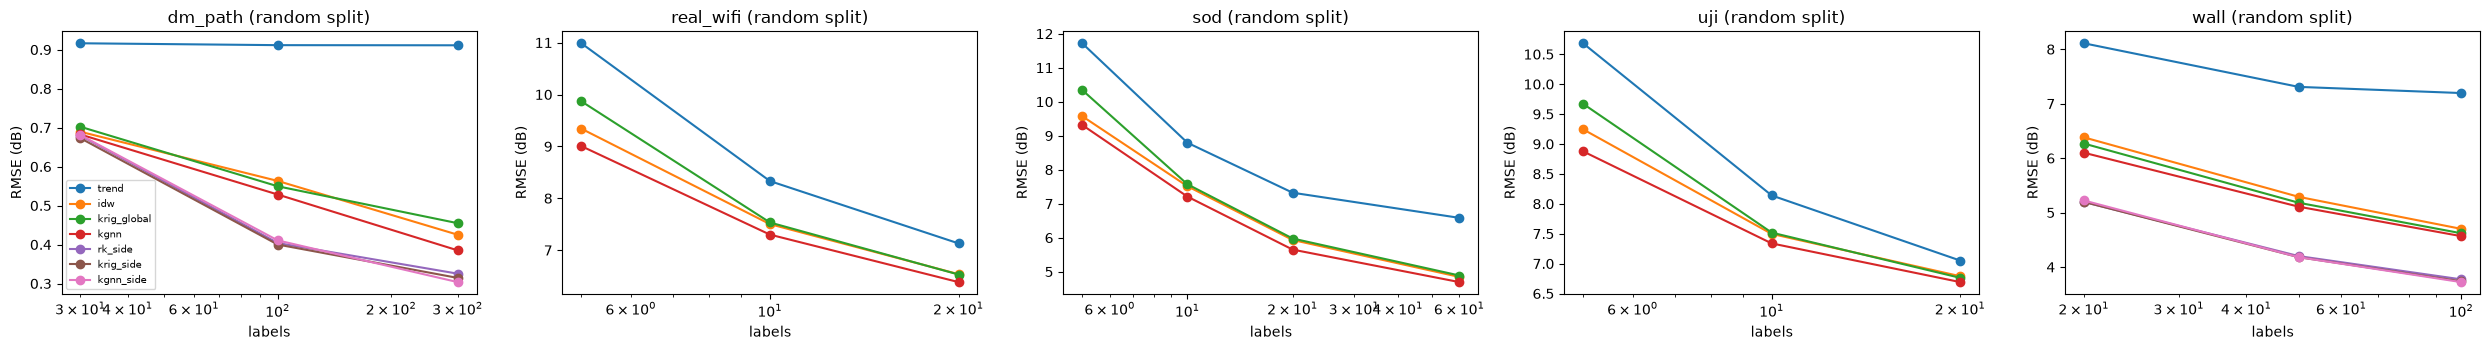

144 contrast rows saved to confirmatory_master_conf2.csv (all of them, losses included)


In [14]:
FAMS = [t for t in PRE["families"] if (t, "random") in RESULTS]
fig, axes = plt.subplots(1, len(FAMS), figsize=(5 * len(FAMS), 3.6), squeeze=False)
for ax, tag in zip(axes[0], FAMS):
    t = rx.agg_metric(RESULTS[(tag, "random")], "rmse")
    for m in [c for c in ["trend", "idw", "krig_global", "kgnn", "rk_side", "krig_side", "kgnn_side"] if c in t.columns]:
        s = t[m].reset_index(); s = s.groupby("density")[m].mean(); ax.plot(s.index, s.values, marker="o", label=m)
    ax.set_title(f"{tag} (random split)"); ax.set_xlabel("labels"); ax.set_ylabel("RMSE (dB)"); ax.set_xscale("log")
axes[0][0].legend(fontsize=7); plt.tight_layout(); plt.savefig(f"{ROOT}/rmse_by_density.png", dpi=130); plt.show()
MASTER = r2.master_table(ENTRIES); MASTER.to_csv(f"{ROOT}/confirmatory_master_conf2.csv", index=False)
print(len(MASTER), "contrast rows saved to confirmatory_master_conf2.csv (all of them, losses included)")

## 8. What this round can and cannot establish
* **Evidence, not proof, about KGNN.** If H4 comes back EQUIVALENT or NOT SUPPORTED, the honest statement is that the learned kernel adds nothing measurable over a fitted variogram at these data sizes. If it is SUPPORTED, the effect still has to be read next to its size in percent: round 1 saw 1 to 7% over IDW.
* **Six buildings.** The pooled real-data claim rests on 6 independent buildings. The building-level CI is wide by construction; the cluster bootstrap with so few clusters is itself approximate.
* **Different test sizes.** UJI uses 20 test points per unit, SOD 40; paired contrasts are within-dataset so this does not bias them, but the pooled family mixes them.
* **Wi-Fi, not 6G.** UJI and SOD are 2.4/5 GHz RSS with censored detections (only detected points enter a unit). Nothing here says anything about mmWave or sub-THz propagation.
* **dm_path is not fresh** (same transmitters) and one environment; `wall` is the author's own simulator. Both are reported, neither is evidence about real buildings.
* **Not tested here:** gradient-boosted / random-forest regression on coordinates + covariates, kriging with the true AP position known (SOD ships AP coordinates), and any deep radio-map baseline. A reviewer will ask for at least the first.